<a href="https://colab.research.google.com/github/rr-codes4/Astrophysics_Beginner_projects/blob/main/Milestone_2_Visualizing_JWST_MIRI_Data!.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



*   **Date:** October 20 2026
*   **Day:** Saturday
* **Target:** Carina Nebula (NGC 3324)
* **Instrument:** MIRI (Mid-Infrared Instrument)
* **Data Source:** [JWST-ERO Archive via MAST](https://archive.stsci.edu/hlsp/jwst-ero)
* **Objective:** Visulaizing the FITS file


In [ ]:
!pip install photutils
from astropy.utils.data import download_file
from astropy.io import fits
url = 'https://archive.stsci.edu/hlsps/jwst-ero/hlsp_jwst-ero_jwst_miri_carina_f770w_v1_i2d.fits'
local_path = download_file(url, cache=True)
hdul = fits.open(local_path)
hdul.info()

Filename: /root/.astropy/cache/download/url/ddb516c91d33bc6dec85c7557b2bc6c3/contents
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     352   ()      
  1  SCI           1 ImageHDU        76   (3499, 1196)   float32   
  2  ERR           1 ImageHDU        10   (3499, 1196)   float32   
  3  CON           1 ImageHDU         9   (3499, 1196)   int32   
  4  WHT           1 ImageHDU         9   (3499, 1196)   float32   
  5  VAR_POISSON    1 ImageHDU         9   (3499, 1196)   float32   
  6  VAR_RNOISE    1 ImageHDU         9   (3499, 1196)   float32   
  7  VAR_FLAT      1 ImageHDU         9   (3499, 1196)   float32   
  8  HDRTAB        1 BinTableHDU    816   40R x 403C   [23A, 5A, 3A, 59A, 7A, 13A, 5A, 19A, 7A, 10A, 4A, L, D, D, D, D, 4A, 26A, 32A, 21A, 3A, 3A, D, D, 10A, 12A, 23A, 23A, 26A, 11A, 5A, 3A, 3A, 2A, 1A, 2A, 1A, L, 12A, 21A, 2A, 26A, 20A, 27A, 10A, K, L, L, L, L, 8A, 8A, 5A, D, D, D, D, D, D, 27A, D, D, D, 4A, 8A, D, D, 5A, D

Set DATE-AVG to '2022-06-11T07:01:06.422' from MJD-AVG.
Set DATE-END to '2022-06-11T12:12:35.756' from MJD-END'. [astropy.wcs.wcs]
Set DATE-AVG to '2022-06-11T07:01:06.422' from MJD-AVG.
Set DATE-END to '2022-06-11T12:12:35.756' from MJD-END'.
Set OBSGEO-B to   -34.153526 from OBSGEO-[XYZ].
Set OBSGEO-H to 1696084672.867 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]
Set OBSGEO-B to   -34.153526 from OBSGEO-[XYZ].
Set OBSGEO-H to 1696084672.867 from OBSGEO-[XYZ]'.


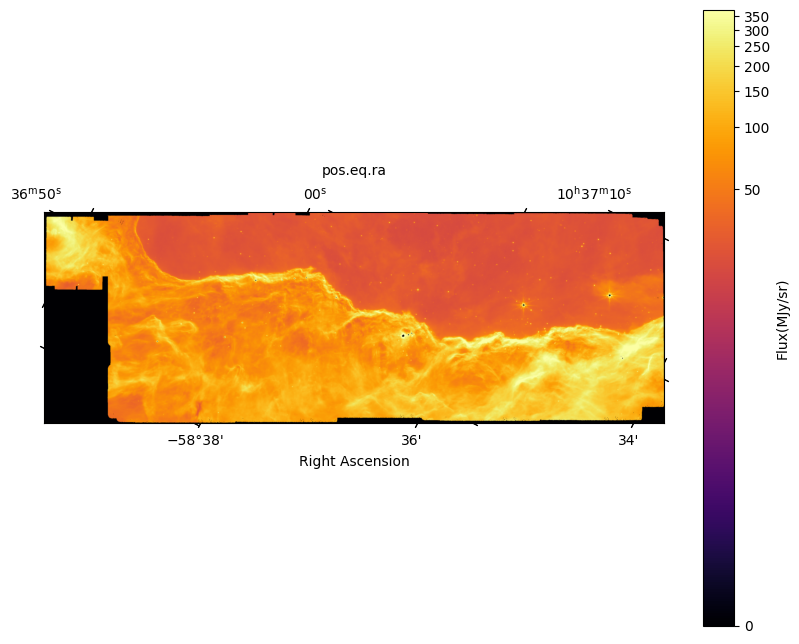

In [ ]:
import matplotlib.pyplot as plt
from astropy.wcs import WCS # importing WCS from astorpy to handle the WCS metadata in the FITS file
from astropy.io import fits #especially for the fits file to read it
from astropy.visualization import SqrtStretch, LogStretch,ImageNormalize """ Discussed """
from astropy.visualization import PercentileInterval   """in the text column below"""
data = hdul['SCI'].data # Stored the info about flux from SCI extension
wcs_header = WCS(hdul['SCI'].header) # tells where is a specific patch of sky located
norm = ImageNormalize(data,interval=PercentileInterval(99.5), stretch=LogStretch()) #crucial,it is responsible to make the gas and dust of the carina nebula

fig, ax = plt.subplots(figsize=(10,8), subplot_kw={'projection': wcs_header})#uses the info from wcs_header and transforms the graph axes into a compelete map
im = ax.imshow(data,origin='lower',norm=norm,cmap='inferno')
ax.set_xlabel('Right Ascension')
ax.set_ylabel('Declination')
plt.colorbar(im,label='Flux(MJy/sr)')
plt.show()

**What I learnt?**
In images like captured by JWST have an exteremely high dynamic range.Using standard FITS tools would'nt be able to see any detail.Hence we used:


*   ImageNormalize : As we would need to stretch or compress the data (like the brightness of specific areas), this tool applies these choices to the raw pixel data so that Matplotlib could display it.

*   LogStretch and SqrtStretch: As the brighter areas could be so bright,the faint details would not be visible.To fix this we use mathematical curve (logarithm & Square Root) and combine with stretching function.LogStretch makes the dark detail more visible,the basic idea is represented by y = log(1+x) ; where x = original brightness value and y = new brightness value.SqrtStretch makes the dim areas more visible y = $\sqrt{x}$.


*   PercentileInterval: To avoid single brightest or darkest pixel dictate the scale,this tool uses clipping to adjust the outlier pixel to a minimum threshold.





**CONCLUSION**
The bright,glowing orange-yellow band showa the dense and hot gas & dust heated by newborn,massive stars.The darker patches are cooler,but they are dense so they block significant amount of light.Since this data is from JWST's MIRI infrared wavelenght cut through the dust revealing what is happening inside and behind it.